<a id="sprint2" name="sprint2"></a>

# Lab01 - Sprint 2

## 7 · Генератор случайных чисел

Лабораторная работа № 1. Прикладная статистика.

[Description](#generator-description) · [Math desc](#generator-math) · [Code](#generator-code) · [Tests](#generator-tests) · [Resume](#generator-resume) · [Lab resume](#generator-lab-resume) · [cat_mark_table](#generator-criteria)

<a id="generator-description" name="generator-description"></a>

### 7.1 · Description

В основе генератора — случайная величина из первого спринта: ASE_NO2, усреднённый за час электрический сигнал электрохимического датчика NO₂ в **мкВ**. Это не концентрация NO₂ в мкг/м³. Источник — Bobbia M., Thulliez E., *Air quality low-cost sensors and monitoring stations NO2 raw dataset in Rouen (France)*, Mendeley Data, version 2, [DOI 10.17632/82dnstrd93.2](https://data.mendeley.com/datasets/82dnstrd93/2), CC BY 4.0. Взята колонка ASE_NO2 файла ASE10.csv. Исключены строки с пропуском ASE_NO2 (53); сохранено 3686 измерений без удаления крайних значений.

Цель — моделировать распределение одного показания и сравнить два способа получения одной и той же случайной величины. Временная зависимость часовых измерений не моделируется. Генерируемые числа не являются прогнозом концентрации или последовательности показаний датчика.

In [1]:
from pathlib import Path
import sys,math,json,hashlib,io,os
from time import perf_counter
from types import SimpleNamespace
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'ASE10.csv').is_file())
GEN_HERE=ROOT/'designer_generator'
GEN_EXPORT=os.environ.get('LAB01_SPRINT2_EXPORT')=='1'
if GEN_EXPORT: (GEN_HERE/'figures').mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_columns',None)
pd.set_option('display.max_colwidth',None)
pd.set_option('display.max_rows',40)
pd.set_option('display.precision',9)
pd.set_option('display.float_format',None)
gen_raw=pd.read_csv(ROOT/'ASE10.csv',sep=';')
gen_data=gen_raw['ASE_NO2'].dropna().to_numpy()
assert len(gen_data)==3686 and len(gen_raw)==len(gen_data)+int(gen_raw.ASE_NO2.isna().sum())

<a id="generator-math" name="generator-math"></a>

### 7.2 · Math desc

Наблюдаемая асимметрия отрицательна. Обычная гамма-модель с положительным масштабом имеет положительную асимметрию и плохо описывает левый хвост. Рассмотрены обычная и отражённая гамма-модели, нормальная и скошенная нормальная модели. Параметры оценены максимизацией логарифма правдоподобия; для отражённой гаммы дополнительно получены оценки методом моментов.

Выбрана учебная аппроксимация



$$
X=b-\theta G,\qquad G\sim\Gamma(a,1),\qquad a>1,\quad\theta>0.
$$



Параметр a безразмерен; b и θ выражены в мкВ. Носитель — x≤b. Граница b относится к модели и не является установленным пределом измерительного прибора. Из замены переменной g=(b−x)/θ и якобиана 1/θ получаем



$$
f_X(x)=\frac{1}{\theta\Gamma(a)}\left(\frac{b-x}{\theta}\right)^{a-1}e^{-(b-x)/\theta},\quad x<b;
\qquad f_X(x)=0,\quad x\geq b.
$$



Неравенство меняет направление при отражении:



$$
F_X(x)=\Pr\{G\geq(b-x)/\theta\}=1-F_G((b-x)/\theta),\quad x<b;
\qquad F_X(x)=1,\quad x\geq b.
$$



В вычислениях используется survival function, чтобы не вычитать близкие к единице числа. Теоретические характеристики:



$$
\mathrm E X=b-a\theta,\quad \mathrm{Var}(X)=a\theta^2,\quad
\gamma_1(X)=-2/\sqrt a,\quad Q_X(p)=b-\theta Q_G(1-p).
$$



Для оценивания MLE гамма-распределение подбирается к −X: его сдвиг равен −b. Для метода моментов используются эмпирические центральные моменты с делителем n:



$$
m_k=\frac1n\sum_i(x_i-\bar x)^k,\qquad
g_1=m_3/m_2^{3/2},\quad
\hat a_{MM}=4/g_1^2,\quad
\hat\theta_{MM}=\sqrt{m_2/\hat a_{MM}},\quad
\hat b_{MM}=\bar x+\hat a_{MM}\hat\theta_{MM}.
$$



Оценки MLE: a=5,452535, b=29322,206090 мкВ, θ=38,582131 мкВ. Модель даёт среднее 29111,835670 мкВ, SD 90,091838 мкВ и асимметрию -0,856507. В данных: 29111,835658 мкВ, 90,419627 мкВ и -0,839532. Разность дисперсий модели и данных составляет -0,724%. Для отражённой гаммы D=0,020284, для скошенной нормальной D=0,013253; AIC соответственно 43174,761 и 43156,377.

Скошенная нормальная модель имеет меньшие AIC и расстояние D. Отражённая гамма выбрана для содержательного продолжения исследования алгоритмов А и GD, а не как победитель сравнения законов. Её близость по среднему, дисперсии и асимметрии оценивается количественно ниже. AIC и D здесь — описательные критерии на данных подгонки. D не превращается в стандартный KS p-value: параметры оценены по той же выборке, а исходные часовые наблюдения могут зависеть во времени.

<a id="generator-code" name="generator-code"></a>

### 7.3 · Code

**Алгоритм А.** Для a>1 берём два независимых U,V с равномерным распределением на (0,1). Предложение Коши и кандидат имеют вид



$$
Y=\tan(\pi U),\quad c=\sqrt{2a-1},\quad Z=a-1+cY.
$$



При Z≤0 предложение отклоняется. Иначе принимаем Z, если



$$
V\leq(1+Y^2)\exp\left((a-1)\log\frac{Z}{a-1}-cY\right).
$$



Это метод отбраковки из алгоритма А Кнута. Если h — плотность предложения, а M h≥f_G, то плотность принятых значений пропорциональна h(z)f_G(z)/(M h(z))=f_G(z)/M; после нормировки получается гамма-плотность. Указанное условие принятия — это отношение f_G/(M h) при



$$
M=\frac{\pi c(a-1)^{a-1}e^{-(a-1)}}{\Gamma(a)}.
$$



**Алгоритм GD.** Используется полный метод Ahrens–Dieter: немедленное принятие, squeeze-проверка, проверка отношения плотностей и заключительное предложение из экспоненциальной оболочки. Полагаем s=√(a−1/2), а нормальное предложение T преобразуем в Z=(s+T/2)². При T≥0 кандидат принимается сразу. Для T<0 сначала применяем дешёвую squeeze-проверку, затем вычисляем логарифм отношения преобразованной гамма-плотности к нормальной.

Плотность преобразованной переменной и логарифмическая проверка основаны на



$$
g(t)=\frac{(s+t/2)^{2a-1}e^{-(s+t/2)^2}}{\Gamma(a)},\quad t>-2s,
$$





$$
Q(t)=q_0-st+t^2/4+2s^2\log(1+t/(2s)),\quad
q_0=\log\frac{\sqrt{2\pi}\,s^{2a-1}e^{-s^2}}{\Gamma(a)}.
$$



Если нормальное предложение не принято, оно заменяется предложением из двухсторонней экспоненциальной оболочки. Для E∼Exp(1), U∼U(−1,1) строится t=B+sign(U)SE. После проверки области t≥−0,71874483771719 и Q>0 используется условие



$$
C|U|\leq (e^{Q(t)}-1)e^{E-t^2/2}.
$$



Константы B,S,C зависят от a; полиномиальные коэффициенты и три диапазона a приведены в коде по опубликованному GD. Этот шаг покрывает хвост, который нельзя получить простым повторением нормального предложения. После любого принятия возвращается Z=(s+t/2)². Для обоих алгоритмов только затем применяется X=b−θZ.

In [2]:
"""Gamma samplers from uniform/normal primitives, using independent RNG objects.

A: Knuth, The Art of Computer Programming, vol. 2, section 3.4.1, algorithm A.
GD: Ahrens & Dieter (1982), doi:10.1145/358315.358390. The polynomial
coefficients and all three acceptance stages are specified by that algorithm.
The R GammaDist reference documents an independent production implementation:
https://stat.ethz.ch/R-manual/R-devel/library/stats/html/GammaDist.html
This module is an independently written Python implementation of the method.
"""

import math
import numpy as np


def _polynomial_without_constant(z, coefficients):
    result = 0.
    for coefficient in reversed(coefficients):
        result = z * (coefficient + result)
    return result


def _positive_uniform(rng):
    value = rng.random()
    while value == 0:
        value = rng.random()
    return value


def gamma_a(n, a, rng):
    """Knuth A, for a > 1: Cauchy proposal followed by rejection."""
    if not isinstance(n, int) or n < 1 or not math.isfinite(a) or a <= 1:
        raise ValueError('A requires a positive integer n and a > 1.')
    values = np.empty(n)
    coefficient = math.sqrt(2*a - 1)
    completed = proposals = uniforms = 0
    while completed < n:
        proposals += 1
        uniforms += 1
        tangent = math.tan(math.pi * rng.random())
        candidate = a - 1 + coefficient*tangent
        if candidate <= 0:
            continue
        uniforms += 1
        log_acceptance = (math.log1p(tangent*tangent)
                          + (a-1)*math.log(candidate/(a-1)) - coefficient*tangent)
        if math.log(_positive_uniform(rng)) <= log_acceptance:
            values[completed] = candidate
            completed += 1
    return values, {'proposals': proposals, 'uniforms': uniforms, 'normals': 0, 'hat_proposals': 0}


def gamma_gd(n, a, rng):
    """Full Ahrens--Dieter GD, a >= 1, including the exponential hat stage."""
    if not isinstance(n, int) or n < 1 or not math.isfinite(a) or a < 1:
        raise ValueError('GD requires a positive integer n and a >= 1.')
    s2 = a-.5
    s = math.sqrt(s2)
    squeeze = math.sqrt(32)-12*s
    q0 = _polynomial_without_constant(1/a,
          (.04166669, .02083148, .00801191, .00144121, -.00007388, .00024511, .0002424))
    quotient_coefficients = (.3333333, -.250003, .2000062, -.1662921, .1423657, -.1367177, .1233795)
    if a <= 3.686:
        center, laplace_scale, envelope = .463+s+.178*s2, 1.235, .195/s-.079+.16*s
    elif a <= 13.022:
        center, laplace_scale, envelope = 1.654+.0076*s2, 1.68/s+.275, .062/s+.024
    else:
        center, laplace_scale, envelope = 1.77, .75, .1515/s

    def quotient(t):
        v = t/(2*s)
        if abs(v) <= .25:
            return q0 + .5*t*t*_polynomial_without_constant(v, quotient_coefficients)
        return q0 - s*t + .25*t*t + 2*s2*math.log1p(v)

    values = np.empty(n)
    proposals = uniforms = normals = hats = 0
    for i in range(n):
        normals += 1
        proposals += 1
        t = float(rng.standard_normal())
        root = s + .5*t
        accepted = t >= 0
        if not accepted:
            uniforms += 1
            u = rng.random()
            accepted = squeeze*u <= t*t*t
            if not accepted and root > 0:
                accepted = math.log1p(-u) <= quotient(t)
        if not accepted:
            # Rejected normal candidates are replaced by the exponential hat,
            # not by restarting normal sampling. This stage supplies the tail.
            while True:
                hats += 1
                proposals += 1
                uniforms += 2
                exponential = -math.log(_positive_uniform(rng))
                signed_uniform = 2*rng.random()-1
                t = center + math.copysign(laplace_scale*exponential, signed_uniform)
                if t < -.71874483771719:
                    continue
                q = quotient(t)
                if q <= 0:
                    continue
                # log(expm1(q)) is evaluated without overflow for large q.
                log_w = math.log(math.expm1(q)) if q < 50 else q + math.log1p(-math.exp(-q))
                left = -math.inf if signed_uniform == 0 else math.log(envelope*abs(signed_uniform))
                if left <= log_w + exponential - .5*t*t:
                    root = s + .5*t
                    break
        values[i] = root*root
    return values, {'proposals': proposals, 'uniforms': uniforms, 'normals': normals, 'hat_proposals': hats}

algorithms=SimpleNamespace(gamma_a=gamma_a,gamma_gd=gamma_gd)

In [3]:
def _values(data):
    x = np.asarray(data, dtype=float)
    if x.ndim != 1 or len(x) < 3 or not np.isfinite(x).all() or np.ptp(x) == 0:
        raise ValueError('At least three finite, nonconstant observations are required.')
    return x

def fit_parameters(data):
    """MLE for X=b-theta*G, by fitting Gamma to -X."""
    a, location, theta = stats.gamma.fit(-_values(data), method='MLE')
    return float(a), float(-location), float(theta)

def moment_parameters(data):
    x = _values(data)
    skew = float(stats.skew(x, bias=True))
    if skew >= 0:
        raise ValueError('Reflected-gamma moment estimates require negative skewness.')
    a = 4 / skew**2
    theta = math.sqrt(float(x.var(ddof=0)) / a)
    return a, float(x.mean()) + a*theta, theta

def model_cdf(x, a, b, theta):
    return stats.gamma.sf((b-np.asarray(x))/theta, a)

def model_pdf(x, a, b, theta):
    return stats.gamma.pdf((b-np.asarray(x))/theta, a) / theta

def model_quantile(p, a, b, theta):
    return b-theta*stats.gamma.isf(p, a)

def theoretical(a, b, theta, n=None):
    return {'n': n, 'sum': None if n is None else n*(b-a*theta),
            'mean': b-a*theta, 'median': float(model_quantile(.5,a,b,theta)),
            'std': math.sqrt(a)*theta, 'variance': a*theta**2,
            'skew': -2/math.sqrt(a), 'q05': float(model_quantile(.05,a,b,theta)),
            'q95': float(model_quantile(.95,a,b,theta)),
            'min': None, 'max': b, 'modes': [], 'mode_frequency': None,
            'density_mode': b-theta*(a-1) if a>1 else b}

def summary(data):
    x = _values(data)
    unique, counts = np.unique(x, return_counts=True)
    frequency = int(counts.max())
    return {'n': len(x), 'sum': float(x.sum()), 'mean': float(x.mean()),
            'median': float(np.median(x)), 'std': float(x.std(ddof=1)),
            'variance': float(x.var(ddof=1)), 'skew': float(stats.skew(x,bias=False)),
            'min': float(x.min()), 'max': float(x.max()),
            'q05': float(np.quantile(x,.05)), 'q95': float(np.quantile(x,.95)),
            'modes': unique[counts==frequency].tolist() if frequency>1 else [],
            'mode_frequency': frequency}

def compare_models(data):
    x = _values(data)
    a,b,theta = fit_parameters(x)
    ma,mb,mt = moment_parameters(x)
    alpha,loc,scale = stats.skewnorm.fit(x)
    ga,gl,gt = stats.gamma.fit(x)
    mu,sd = stats.norm.fit(x)
    specifications = [
        ('Отражённая гамма, MLE','reflected_gamma','MLE',(a,b,theta),3,
         lambda z:model_cdf(z,a,b,theta), lambda z:stats.gamma.logpdf(-z,a,-b,theta),
         theoretical(a,b,theta)),
        ('Отражённая гамма, моменты','reflected_gamma_moments','moments',(ma,mb,mt),None,
         lambda z:model_cdf(z,ma,mb,mt),lambda z:stats.gamma.logpdf(-z,ma,-mb,mt),theoretical(ma,mb,mt)),
        ('Скошенная нормальная, MLE','skew_normal','MLE',(alpha,loc,scale),3,
         lambda z:stats.skewnorm.cdf(z,alpha,loc,scale),lambda z:stats.skewnorm.logpdf(z,alpha,loc,scale),
         {'mean':float(stats.skewnorm.mean(alpha,loc,scale)), 'std':float(stats.skewnorm.std(alpha,loc,scale)),
          'variance':float(stats.skewnorm.var(alpha,loc,scale)), 'skew':float(stats.skewnorm.stats(alpha,loc,scale,moments='s'))}),
        ('Обычная гамма, MLE','right_gamma','MLE',(ga,gl,gt),3,
         lambda z:stats.gamma.cdf(z,ga,gl,gt),lambda z:stats.gamma.logpdf(z,ga,gl,gt),
         {'mean':gl+ga*gt,'std':math.sqrt(ga)*gt,'variance':ga*gt**2,'skew':2/math.sqrt(ga)}),
        ('Нормальная, MLE','normal','MLE',(mu,sd),2,
         lambda z:stats.norm.cdf(z,mu,sd),lambda z:stats.norm.logpdf(z,mu,sd),
         {'mean':mu,'std':sd,'variance':sd**2,'skew':0.})]
    records=[]
    for name,key,estimation,parameters,k,cdf,logpdf,moments in specifications:
        likelihood=float(np.sum(logpdf(x)))
        records.append({'name':name,'key':key,'estimation':estimation,
                        'parameters':[float(p) for p in parameters],
                        'D_data':float(stats.ks_1samp(x,cdf).statistic),
                        'log_likelihood':likelihood,'AIC':None if k is None else 2*k-2*likelihood,
                        **{key:float(value) for key,value in moments.items() if key in ['mean','std','variance','skew']}})
    return records

def generate(method,n,a,b,theta,seed):
    if method not in ('A','GD') or not isinstance(n,int) or not 1<=n<=20000:
        raise ValueError('Choose A or GD and integer N from 1 to 20000.')
    if not all(np.isfinite(v) for v in (a,b,theta)) or not 1<a<=1000 or abs(b)>1e9 or not 1e-6<=theta<=1e6:
        raise ValueError('Require 1<a<=1000, |b|<=1e9 and 1e-6<=theta<=1e6.')
    if not isinstance(seed,int) or not 0<=seed<2**32:
        raise ValueError('Seed must be an integer from 0 through 2**32-1.')
    rng=np.random.default_rng(seed)
    start=perf_counter()
    gamma,counts=(algorithms.gamma_a if method=='A' else algorithms.gamma_gd)(n,a,rng)
    elapsed=perf_counter()-start
    values=b-theta*gamma
    return {'values':values,'gamma_values':gamma,'attempts':counts['proposals'],
            'acceptance':n/counts['proposals'],'seconds':elapsed,**counts,
            'support_violations':int(np.count_nonzero(values>b))}

def diagnostics(values,a,b,theta,data=None):
    x=np.asarray(values)
    result={'D к модели':float(stats.ks_1samp(x,lambda z:model_cdf(z,a,b,theta)).statistic),
            'Асимметрия':float(stats.skew(x,bias=False)),
            'Значений выше b':int(np.count_nonzero(x>b))}
    if data is not None:
        result['D к данным']=float(stats.ks_2samp(x,np.asarray(data)).statistic)
    return result

def comparison_table(data,runs,a,b,theta):
    observed=summary(data)
    rows={'Данные':observed,'Модель':theoretical(a,b,theta,len(data))}
    rows.update({method:summary(run['values']) for method,run in runs.items()})
    keys=[('n','N'),('sum','Сумма, мкВ'),('mean','Среднее, мкВ'),('median','Медиана, мкВ'),
          ('std','Стандартное отклонение, мкВ'),('variance','Дисперсия, мкВ²'),('skew','Асимметрия'),
          ('q05','5-й процентиль, мкВ'),('q95','95-й процентиль, мкВ'),('min','Минимум, мкВ'),('max','Максимум, мкВ'),('modes','Эмпирические моды, мкВ')]
    if any(len(run['values'])!=len(data) for run in runs.values()):
        keys=[item for item in keys if item[0]!='sum']
    records=[]
    for key,label in keys:
        record={'Показатель':label}
        for name,row in rows.items():
            value=row.get(key)
            if key=='modes':
                value='Нет повторов' if not value else '; '.join(f'{v:.6g}' for v in value)
                if name=='Модель': value='—'
            elif key=='max' and name=='Модель': value=f'Граница b = {b:.9g}'
            elif value is None: value='—'
            elif key=='n': value=str(value)
            else: value=f'{value:.9g}'
            record[name]=value
        records.append(record)
    return pd.DataFrame(records)

def sampling_intervals(n,a,b,theta,repetitions=600,seed=20261113):
    """95% Monte Carlo prediction bands for sample statistics at fixed parameters.

    Reference Gamma sampling is used only for calibration, not as A or GD.
    These are not parameter CIs and not fitted-distribution goodness-of-fit tests.
    """
    rng=np.random.default_rng(seed)
    samples=b-theta*rng.gamma(a,size=(repetitions,n))
    statistics={'mean':samples.mean(axis=1),'std':samples.std(axis=1,ddof=1),
                'variance':samples.var(axis=1,ddof=1),'skew':stats.skew(samples,axis=1,bias=False),
                'q05':np.quantile(samples,.05,axis=1),'q95':np.quantile(samples,.95,axis=1)}
    return {key:{'low':float(np.quantile(value,.025)), 'high':float(np.quantile(value,.975))}
            for key,value in statistics.items()}

In [4]:
def scientific_checks(algorithms,n=40000,seed=20261113):
    epsilon=math.sqrt(math.log(2/1e-6)/(2*n))
    rows=[]
    for name,fn in [('A',algorithms.gamma_a),('GD',algorithms.gamma_gd)]:
        for a in [1.01,3.,5.4525349587,200.]:
            x,counts=fn(n,a,np.random.default_rng(seed))
            distance=float(stats.ks_1samp(x,lambda z:stats.gamma.cdf(z,a)).statistic)
            mean_error=abs(float(x.mean())-a)
            variance_error=abs(float(x.var(ddof=1))-a)
            mean_bound=6*math.sqrt(a/n)
            variance_bound=6*math.sqrt((2*a*a+6*a)/n)
            assert np.all(x>0) and np.isfinite(x).all()
            assert distance<epsilon and mean_error<mean_bound and variance_error<variance_bound
            rows.append({'Метод':name,'a':a,'N':n,'D к Γ(a,1)':distance,'Граница DKW':epsilon,
                         '|ошибка среднего|':mean_error,'Допуск среднего, 6SE':mean_bound,
                         '|ошибка дисперсии|':variance_error,'Допуск дисперсии, 6SE':variance_bound,
                         'Вне поддержки':int(np.sum(x<0)),'Кандидатов оболочки':counts['hat_proposals']})
    return rows

def benchmark(generate,n,a,b,theta,repeats=7,seed=40):
    rows=[]
    for method in ['A','GD']:
        elapsed=[]; proposals=[]
        for repeat in range(repeats):
            run=generate(method,n,a,b,theta,seed+repeat)
            elapsed.append(run['seconds']); proposals.append(run['proposals'])
        rows.append({'Метод':method,'N':n,'Повторений':repeats,'Медиана времени, с':float(np.median(elapsed)),
                     'Q25 времени, с':float(np.quantile(elapsed,.25)),'Q75 времени, с':float(np.quantile(elapsed,.75)),
                     'Медиана кандидатов':float(np.median(proposals))})
    return rows

def interval_table(data,runs,parameters,bands,summary,theoretical):
    a,b,theta=parameters
    moments=theoretical(a,b,theta,len(data)); observed=summary(data)
    labels={'mean':'Среднее, мкВ','std':'SD, мкВ','variance':'Дисперсия, мкВ²','skew':'Асимметрия','q05':'5-й процентиль, мкВ','q95':'95-й процентиль, мкВ'}
    records=[]
    for key,label in labels.items():
        row={'Показатель':label,'Данные':observed[key],'Модель':moments[key],
             'Данные − модель':observed[key]-moments[key],
             '95% нижняя':bands[key]['low'],'95% верхняя':bands[key]['high']}
        row.update({name:summary(run['values'])[key] for name,run in runs.items()})
        records.append(row)
    return records

def _style():
    return plt.rc_context({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,
                           'axes.grid':True,'grid.alpha':.2,'figure.facecolor':'white','axes.facecolor':'white'})

def figure_models(data,models,model_pdf,model_cdf):
    with _style():
        fig,axes=plt.subplots(1,2,figsize=(11,4.3))
        grid=np.linspace(min(data)-50,max(data)+65,700)
        axes[0].plot(grid,stats.gaussian_kde(data)(grid),color='#64748b',label='Данные, KDE')
        ordered=np.sort(data)
        axes[1].step(ordered,np.arange(1,len(ordered)+1)/len(ordered),where='post',color='#64748b',label='Данные, ECDF')
        for key,color,label in [('reflected_gamma','#245c7a','Отражённая гамма'),('skew_normal','#a57240','Скошенная нормальная'),('right_gamma','#85978b','Обычная гамма')]:
            row=next(r for r in models if r['key']==key); p=row['parameters']
            if key=='reflected_gamma': pdf,cdf=model_pdf(grid,*p),model_cdf(grid,*p)
            elif key=='skew_normal': pdf,cdf=stats.skewnorm.pdf(grid,*p),stats.skewnorm.cdf(grid,*p)
            else: pdf,cdf=stats.gamma.pdf(grid,*p),stats.gamma.cdf(grid,*p)
            axes[0].plot(grid,pdf,color=color,label=label); axes[1].plot(grid,cdf,color=color,label=label)
        axes[0].set(title='Плотности',ylabel='Плотность, 1/мкВ',xlabel='ASE_NO2, мкВ')
        axes[1].set(title='Функции распределения',ylabel='F(x)',xlabel='ASE_NO2, мкВ',ylim=(0,1.02))
        for axis in axes: axis.legend(fontsize=8)
        fig.tight_layout(pad=1.6)
        return fig

def figure_generators(data,runs,parameters,model_pdf,model_cdf):
    with _style():
        fig,axes=plt.subplots(1,2,figsize=(11,4.3))
        values=np.r_[data,*[r['values'] for r in runs.values()]]
        grid=np.linspace(values.min()-10,max(values.max()+10,parameters[1]+5),700)
        for x,label,color in [(data,'Данные','#64748b'),(runs['A']['values'],'Алгоритм А','#245c7a'),(runs['GD']['values'],'Алгоритм GD','#a57240')]:
            axes[0].plot(grid,stats.gaussian_kde(x)(grid),color=color,label=label)
            ordered=np.sort(x); axes[1].step(ordered,np.arange(1,len(x)+1)/len(x),where='post',color=color,label=label)
        axes[0].plot(grid,model_pdf(grid,*parameters),'--',color='#334155',label='Модель')
        axes[1].plot(grid,model_cdf(grid,*parameters),'--',color='#334155',label='Модель')
        axes[0].set(title='Плотности',ylabel='Плотность, 1/мкВ',xlabel='ASE_NO2, мкВ')
        axes[1].set(title='Функции распределения',ylabel='F(x)',xlabel='ASE_NO2, мкВ',ylim=(0,1.02))
        for axis in axes: axis.legend(fontsize=8)
        fig.tight_layout(pad=1.6)
        return fig

def figure_intervals(rows):
    with _style():
        fig,axes=plt.subplots(1,2,figsize=(10,4))
        for axis,index,title in zip(axes,[0,2],['Среднее, мкВ','Дисперсия, мкВ²']):
            row=rows[index]
            axis.axvspan(row['95% нижняя'],row['95% верхняя'],color='#dbe5ec',label='95% выборочный диапазон')
            for i,(label,color) in enumerate([('Данные','#64748b'),('Модель','#334155'),('A','#245c7a'),('GD','#a57240')]):
                axis.scatter(row[label],i,color=color,s=48,label=label)
            axis.set(yticks=range(4),yticklabels=['Данные','Модель','А','GD'],xlabel=title,title=title)
        fig.tight_layout(pad=1.6)
        return fig

<a id="gen-table-11" name="gen-table-11"></a>

**Таблица 11 · Модели и оценки.** Для MLE приведён AIC=2k−2log L, где k — число оценённых параметров. Метод моментов показан отдельной строкой без AIC-сравнения. Меньший D означает меньшее максимальное расстояние между ECDF наблюдений и CDF модели.

In [5]:
gen_parameters=fit_parameters(gen_data)
gen_models=compare_models(gen_data)
gen_model_table=pd.DataFrame([{'Модель':r['name'],'Параметры':', '.join(f'{p:.9g}' for p in r['parameters']),
    'Среднее, мкВ':r['mean'],'SD, мкВ':r['std'],'Асимметрия':r['skew'],'D':r['D_data'],
    'AIC':'—' if r['AIC'] is None else f"{r['AIC']:.6f}"} for r in gen_models])
display(gen_model_table)

,Модель,Параметры,"Среднее, мкВ","SD, мкВ",Асимметрия,D,AIC
0,"Отражённая гамма, MLE","5.45253496, 29322.2061, 38.5821315",29111.835669817,90.091837689,-0.856506703,0.020284120,43174.760778
1,"Отражённая гамма, моменты","5.67987351, 29327.2989, 37.9345084",29111.835657759,90.407360955,-0.839190703,0.020957685,—
2,"Скошенная нормальная, MLE","-4.11592347, 29221.7477, 142.317021",29111.405111959,89.881355841,-0.794115222,0.013252783,43156.376953
3,"Обычная гамма, MLE","202.40228, 27756.8728, 6.69607838",29112.174320465,95.263871837,0.140579597,0.079736528,43832.747661
4,"Нормальная, MLE","29111.8357, 90.407361",29111.835657759,90.407360955,0.000000000,0.072856464,43670.303858


<a id="gen-figure-17" name="gen-figure-17"></a>

**Рисунок 17 · Сравнение моделей.** Показаны KDE и ECDF наблюдений, обычная гамма, отражённая гамма и скошенная нормальная. Сглаживание служит визуализации; расстояние D вычислено по несглаженным данным.

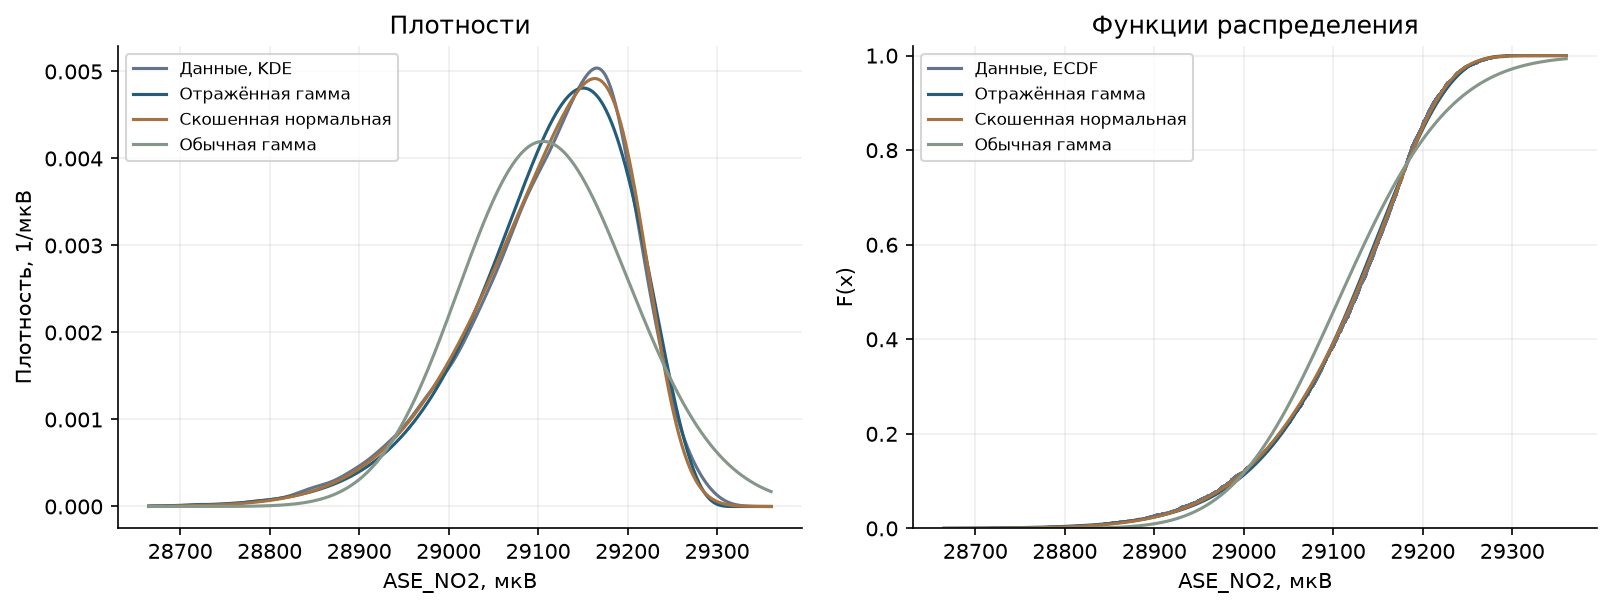

In [6]:
gen_fig=figure_models(gen_data,gen_models,model_pdf,model_cdf)
gen_buffer=io.BytesIO(); gen_fig.savefig(gen_buffer,format='png',dpi=150,bbox_inches='tight',facecolor='white')
if GEN_EXPORT: (GEN_HERE/'figures/gen01-models.png').write_bytes(gen_buffer.getvalue())
plt.close(gen_fig); display(Image(data=gen_buffer.getvalue()))

<a id="generator-tests" name="generator-tests"></a>

### 7.4 · Tests

<a id="gen-table-12" name="gen-table-12"></a>

**Таблица 12 · Данные, теория и генераторы.** Для А и GD взято N=3686, как у реальных данных; seed=40. Поэтому суммы сравнимы. Выборочная дисперсия и SD используют делитель n−1. Перечисляются все моды с наибольшей частотой; при уникальных значениях единственная эмпирическая мода отсутствует. Плотностная мода непрерывной модели и эмпирические моды имеют разный смысл. Верхняя граница b не является ожидаемым максимумом конечной выборки.

In [7]:
gen_seed=40
gen_runs={method:generate(method,len(gen_data),*gen_parameters,gen_seed) for method in ['A','GD']}
gen_metrics={'data':summary(gen_data),'model':theoretical(*gen_parameters,len(gen_data)),
             **{method:summary(run['values']) for method,run in gen_runs.items()}}
display(comparison_table(gen_data,gen_runs,*gen_parameters))


,Показатель,Данные,Модель,A,GD
0,N,3686,3686,3686,3686
1,"Сумма, мкВ",107306226,107306226,107309827,107311905
2,"Среднее, мкВ",29111.8357,29111.8357,29112.8125,29113.3763
3,"Медиана, мкВ",29128.0381,29124.5472,29124.4108,29124.4059
4,"Стандартное отклонение, мкВ",90.4196271,90.0918377,88.26141,88.9734863
5,"Дисперсия, мкВ²",8175.70896,8116.53922,7790.07649,7916.28127
6,Асимметрия,-0.839532385,-0.856506703,-0.788078307,-0.859434309
7,"5-й процентиль, мкВ",28939.9492,28945.1421,28949.9414,28947.6183
8,"95-й процентиль, мкВ",29233.1652,29235.1296,29235.1878,29234.2783
9,"Минимум, мкВ",28715,—,28583.3947,28695.6058


<a id="gen-table-13" name="gen-table-13"></a>

**Таблица 13 · Качество генерации.** D к модели сравнивает генератор с заданной CDF; D к данным сравнивает синтетическую и реальную выборки. Проверяется отсутствие значений выше b.

In [8]:

gen_diagnostics={method:diagnostics(run['values'],*gen_parameters,gen_data) for method,run in gen_runs.items()}
display(pd.DataFrame(gen_diagnostics).T)


,D к модели,Асимметрия,Значений выше b,D к данным
A,0.011845486,-0.788078307,0.0,0.020889853
GD,0.013902815,-0.859434309,0.0,0.019262073


<a id="gen-table-14" name="gen-table-14"></a>

**Таблица 14 · Расхождения и выборочная вариабельность.** Для фиксированных оценённых параметров сформированы 600 эталонных выборок того же объёма и получены 2,5%-й и 97,5%-й квантили каждой статистики. Это 95%-й диапазон выборочной вариабельности при заданной модели, а не доверительный интервал параметров и не проверка истинности подобранного закона. Числа генераторов не обязаны точно совпадать с теорией или исходной выборкой.

In [9]:

gen_bands=sampling_intervals(len(gen_data),*gen_parameters,repetitions=600,seed=20261113)
gen_interval_rows=interval_table(gen_data,gen_runs,gen_parameters,gen_bands,summary,theoretical)
display(pd.DataFrame(gen_interval_rows))


,Показатель,Данные,Модель,Данные − модель,95% нижняя,95% верхняя,A,GD
0,"Среднее, мкВ",29111.835657759,29111.835669817,-0.000012058,29108.729802267,29114.750531810,29112.812503667,29113.376316995
1,"SD, мкВ",90.419627064,90.091837689,0.327789376,87.431099365,92.442298578,88.261409995,88.973486330
2,"Дисперсия, мкВ²",8175.708958474,8116.539218164,59.169740310,7644.197141749,8545.578567217,7790.076494269,7916.281269761
3,Асимметрия,-0.839532385,-0.856506703,0.016974319,-0.987691336,-0.739958241,-0.788078307,-0.859434309
4,"5-й процентиль, мкВ",28939.949220000,28945.142148207,-5.192928207,28935.909865295,28954.245200956,28949.941448512,28947.618321568
5,"95-й процентиль, мкВ",29233.165215000,29235.129604911,-1.964389911,29231.869636430,29238.345905932,29235.187804126,29234.278309359


<a id="gen-table-15" name="gen-table-15"></a>

**Таблица 15 · Проверка закона генерации.** Проверка самих алгоритмов проводится отдельно от подгонки данных: восемь выборок по 40 000 значений, a∈{1,01;3;5,452535;200}. Проверяются положительность G, конечность чисел, среднее, дисперсия и CDF. Допуск среднего равен 6√(a/N); для дисперсии используется 6√((2a²+6a)/N). Для ECDF используется граница Дворецкого—Кифера—Вольфовица при δ=10⁻⁶ для каждой отдельной выборки:



$$
\varepsilon=\sqrt{\log(2/\delta)/(2N)},\qquad
\Pr\{\sup_x|\widehat F_N(x)-F(x)|>\varepsilon\}\leq\delta.
$$



Одинаковые формулы допусков используются для каждой пары «алгоритм — a». При подстановке a,b,θ в отражение проверяются X≤b и обратимость CDF/квантилей; повторный seed должен повторять числа. Полный набор воспроизводимых проверок находится в [test_generator.py](test_generator.py).

In [10]:

gen_checks=scientific_checks(algorithms,n=40000,seed=20261113)
gen_check_table=pd.DataFrame([{'Метод':r['Метод'],'a':r['a'],'N':r['N'],'D':r['D к Γ(a,1)'],'Граница DKW':r['Граница DKW'],
    'Ошибка среднего / допуск':r['|ошибка среднего|']/r['Допуск среднего, 6SE'],
    'Ошибка дисперсии / допуск':r['|ошибка дисперсии|']/r['Допуск дисперсии, 6SE'],'Вне поддержки':r['Вне поддержки']} for r in gen_checks])
display(gen_check_table)
for method,run in gen_runs.items():
    assert run['support_violations']==0
    repeated=generate(method,len(gen_data),*gen_parameters,gen_seed)
    np.testing.assert_array_equal(run['values'],repeated['values'])

,Метод,a,N,D,Граница DKW,Ошибка среднего / допуск,Ошибка дисперсии / допуск,Вне поддержки
0,A,1.010000000,40000,0.003242179,0.013466931,0.101856996,0.126207779,0
1,A,3.000000000,40000,0.004554989,0.013466931,0.181425406,0.174005304,0
2,A,5.452534959,40000,0.004421911,0.013466931,0.225637086,0.084740033,0
3,A,200.000000000,40000,0.007667715,0.013466931,0.324475467,0.103061715,0
4,GD,1.010000000,40000,0.004522342,0.013466931,0.188361556,0.053743281,0
5,GD,3.000000000,40000,0.005758394,0.013466931,0.357244905,0.185711013,0
6,GD,5.452534959,40000,0.004846514,0.013466931,0.170026737,0.084176723,0
7,GD,200.000000000,40000,0.005782911,0.013466931,0.283443194,0.157096298,0


<a id="gen-figure-18" name="gen-figure-18"></a>

**Рисунок 18 · Синтетические данные.** Для обеих выборок использованы одинаковые N и параметры модели. Сравнение с реальными данными и сравнение с теорией — разные задачи.

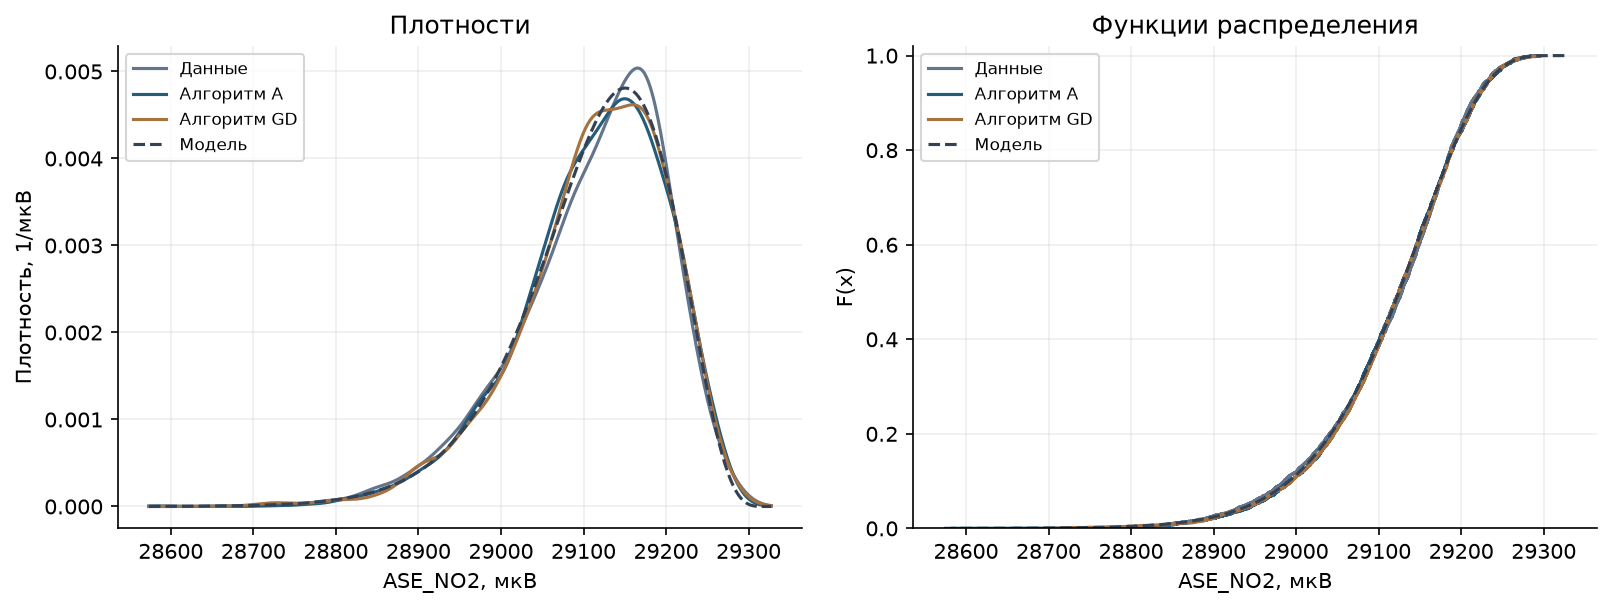

In [11]:
gen_fig=figure_generators(gen_data,gen_runs,gen_parameters,model_pdf,model_cdf)
gen_buffer=io.BytesIO(); gen_fig.savefig(gen_buffer,format='png',dpi=150,bbox_inches='tight',facecolor='white')
if GEN_EXPORT: (GEN_HERE/'figures/gen02-generators.png').write_bytes(gen_buffer.getvalue())
plt.close(gen_fig); display(Image(data=gen_buffer.getvalue()))

<a id="gen-figure-19" name="gen-figure-19"></a>

**Рисунок 19 · Выборочная вариабельность.** Полоса показывает 95%-й диапазон для статистики выборки N=3686 при фиксированной отражённой гамма-модели. Отдельно отмечены реальная выборка, теоретическое значение и результаты А/GD.

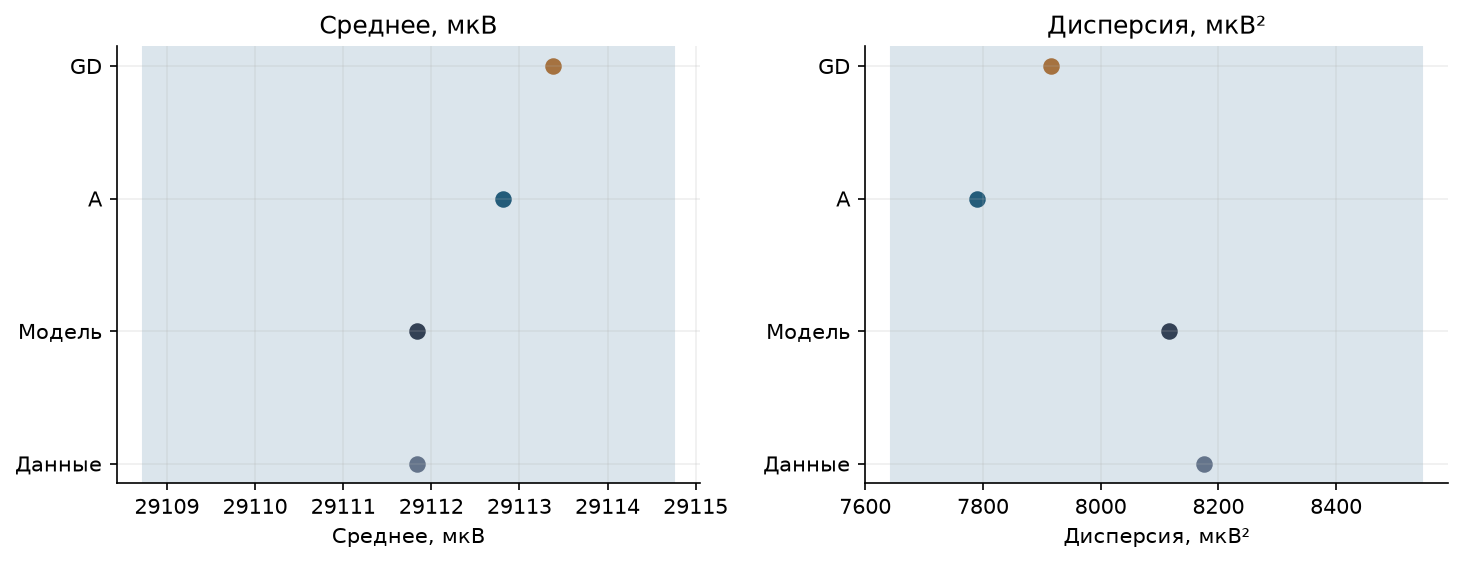

In [12]:
gen_fig=figure_intervals(gen_interval_rows)
gen_buffer=io.BytesIO(); gen_fig.savefig(gen_buffer,format='png',dpi=150,bbox_inches='tight',facecolor='white')
if GEN_EXPORT: (GEN_HERE/'figures/gen03-intervals.png').write_bytes(gen_buffer.getvalue())
plt.close(gen_fig); display(Image(data=gen_buffer.getvalue()))

<a id="gen-table-16" name="gen-table-16"></a>

**Таблица 16 · Исследование алгоритмов.** Для каждого метода выполнены семь запусков N=3686 с seed 40…46. Показаны медиана и квартили времени на данном компьютере. Кандидатом считается каждое нормальное/кошевское предложение или предложение оболочки GD; их вычислительная стоимость различна. Число кандидатов и время поэтому интерпретируются раздельно. Относительная скорость зависит от среды и не является оценкой точности модели.

In [13]:
gen_benchmark=benchmark(generate,len(gen_data),*gen_parameters,repeats=7,seed=gen_seed)
display(pd.DataFrame(gen_benchmark))
gen_result={'study':'Sprint 2: reflected gamma for ASE_NO2','selected_model':'reflected_gamma',
 'data':{'N':len(gen_data),'raw_rows':len(gen_raw),'missing':int(gen_raw.ASE_NO2.isna().sum()),'units':'µV',
         'source':'https://data.mendeley.com/datasets/82dnstrd93/2',
         'csv_sha256_lf':hashlib.sha256((ROOT/'ASE10.csv').read_bytes().replace(b'\r\n',b'\n')).hexdigest()},
 'parameters':dict(zip(['a','b','theta'],gen_parameters)),'models':gen_models,'metrics':gen_metrics,
 'diagnostics':gen_diagnostics,'sampling_intervals':gen_bands,'sampling_repetitions':600,'sampling_seed':20261113,
 'sampling_rows':gen_interval_rows,'distribution_checks':gen_checks,'benchmark':gen_benchmark,'seed':gen_seed}
if GEN_EXPORT:
    (GEN_HERE/'results.json').write_text(json.dumps(gen_result,ensure_ascii=False,indent=2,allow_nan=False)+'\n',encoding='utf8')
    pd.DataFrame({'data':gen_data,'A':gen_runs['A']['values'],'GD':gen_runs['GD']['values']}).to_csv(GEN_HERE/'generated.csv',index=False)
    gen_model_table.to_csv(GEN_HERE/'model_comparison.csv',index=False)
    comparison_table(gen_data,gen_runs,*gen_parameters).to_csv(GEN_HERE/'metrics.csv',index=False)
    pd.DataFrame(gen_interval_rows).to_csv(GEN_HERE/'sampling_intervals.csv',index=False)
    pd.DataFrame(gen_benchmark).to_csv(GEN_HERE/'benchmark.csv',index=False)

,Метод,N,Повторений,"Медиана времени, с","Q25 времени, с","Q75 времени, с",Медиана кандидатов
0,A,3686,7,0.0711271,0.0652899,0.0718393,6757.0
1,GD,3686,7,0.0225438,0.0191787,0.0242889,3843.0


<a id="generator-resume" name="generator-resume"></a>

### 7.5 · Resume

Обычная гамма не передавала отрицательную асимметрию. Отражение позволило получить модель с близкими средним и разбросом, однако скошенная нормальная описывает эту выборку лучше по AIC. Для N=3686 и seed=40 алгоритм А дал среднее 29112,812504 мкВ и дисперсию 7790,076494 мкВ²; GD — 29113,376317 мкВ и 7916,281270 мкВ². Значений выше b нет у обоих методов. В восьми контрольных выборках поддержка, моменты и CDF удовлетворили указанным допускам; это численная проверка реализации, а не доказательство истинности модели реальных данных. Сравнение эффективности приведено для семи запусков на одном компьютере.

<a id="generator-lab-resume" name="generator-lab-resume"></a>

### 7.6 · Lab resume

Для выбранной в первом спринте величины построен генератор её одномерного приближения. Направление асимметрии согласовано с наблюдениями с помощью отражения. Два алгоритма получают одну целевую модель, а проверка их реализации отделена от качества модели данных. Конечная выборка даёт случайные отклонения метрик; точного совпадения всех статистик не заявляется. Исследование не описывает временную зависимость, перенос калибровки датчика или распределение концентрации в мкг/м³.

<a id="generator-criteria" name="generator-criteria"></a>

### 7.7 · cat_mark_table

| cat_id | notebook_link | coeff | comment |
| --- | --- | --- | --- |
| — | [Description](#generator-description) | — | Генерируется электрический сигнал ASE_NO2, мкВ |
| — | [Math desc](#generator-math) | — | Отражённая гамма; сравнение с нормальной, обычной гамма и скошенной нормальной моделями |
| — | [Code](#generator-code) | — | Алгоритм А и полный GD с общим преобразованием X=b−θG |
| — | [Tests](#generator-tests) | — | Метрики при N=3686; поддержка, моменты, CDF и воспроизводимость |
| — | [Исследование алгоритмов](#gen-table-16) | — | По семь запусков А и GD; медиана и квартили времени |
| — | [Resume](#generator-resume), [Lab resume](#generator-lab-resume) | — | Ограничения аппроксимации и итог сравнения |



### Источники и материалы

1. Bobbia M., Thulliez E. Датасет датчиков NO₂, Mendeley Data, version 2. [DOI 10.17632/82dnstrd93.2](https://data.mendeley.com/datasets/82dnstrd93/2).
2. Кнут Д. Э. *Искусство программирования*. Т. 2, § 3.4.1, алгоритм А.
3. Ahrens J. H., Dieter U. *Generating gamma variates by a modified rejection technique*. Communications of the ACM 25(1), 47–54, 1982. [DOI 10.1145/358315.358390](https://doi.org/10.1145/358315.358390). [Референс R: GammaDist](https://stat.ethz.ch/R-manual/R-devel/library/stats/html/GammaDist.html).
4. SciPy. [Gamma](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html), [skew-normal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.skewnorm.html), [MLE и ограничения численного оценивания](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.rv_continuous.fit.html).
5. Massart P. *The tight constant in the Dvoretzky–Kiefer–Wolfowitz inequality*. Annals of Probability 18(3), 1269–1283, 1990. [DOI 10.1214/aop/1176990746](https://doi.org/10.1214/aop/1176990746).

[Приложение](https://marimo.app/github/EastC0ast/lab01/blob/design-layout/designer_generator/browser_app.py/wasm?embed=true&mode=read&include-code=false&show-code=false) · [Исполняемый ноутбук](sprint2_calculations.ipynb) · [Читательский ноутбук](sprint2.ipynb) · [Полные результаты](results.json) · [Код алгоритмов](algorithms.py)

[К оглавлению Sprint 2](#sprint2)